

**Project objective:** Explore how household income is spent, estimate savings, compare household groups, and create clear visualizations.

**Important data note:** This notebook uses two types of data:
1. **Illustrative household records** created for learning. These are not real survey responses and must not be presented as official household data.
2. **Official Indian household consumption figures** from the Government of India's Household Consumption Expenditure Survey (HCES) factsheet, used for a small real-world rural/urban comparison. These are published survey estimates, not live data.

The official HCES measures consumption expenditure, not every household's income. Therefore, the household-level income and savings analysis below is illustrative, while the official comparison is about consumption expenditure.

**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn.

##  Import the libraries

Libraries are collections of ready-made tools. Pandas works with tables, NumPy works with arrays and calculations, Matplotlib and Seaborn make graphs.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


Create the household dataset

To keep the project  we create a small **illustrative** dataset of 20 households.

All amounts are in Indian rupees (₹) per month.

In [ ]:
household_data = {
    "Household_ID": [f"H{i:02d}" for i in range(1, 21)],
    "State": ["Telangana","Telangana","Andhra Pradesh","Karnataka","Maharashtra",
              "Telangana","Kerala","Tamil Nadu","Andhra Pradesh","Karnataka",
              "Maharashtra","Telangana","Kerala","Tamil Nadu","Karnataka",
              "Andhra Pradesh","Telangana","Maharashtra","Tamil Nadu","Kerala"],
    "Area": ["Urban","Rural","Urban","Rural","Urban","Rural","Urban","Rural","Rural","Urban",
             "Rural","Urban","Rural","Urban","Rural","Urban","Rural","Urban","Rural","Urban"],
    "Monthly_Income": [52000,28000,46000,32000,61000,35000,57000,30000,26000,49000,
                       33000,72000,31000,54000,29000,44000,24000,65000,34000,59000],
    "Food": [11000,8000,9500,8500,12500,9000,11500,8200,7500,10000,
             9000,14000,7800,11000,8000,9200,7000,13000,8500,12000],
    "Housing": [10000,4000,9000,3500,13000,4000,12000,3500,3000,9500,
                4000,15000,3500,11000,3500,8000,3000,14000,4000,12500],
    "Transport": [4500,1800,3800,2000,5500,2200,4200,1900,1500,4000,
                  2000,6000,1800,4300,1700,3500,1300,5800,2100,4500],
    "Education": [5000,2500,4000,3000,6500,3000,5500,2800,2200,4500,
                  3000,7000,2600,5000,2500,3500,1800,6000,3000,5200],
    "Healthcare": [1800,1200,1600,1400,2200,1500,2000,1300,1000,1700,
                   1500,2500,1200,1900,1300,1600,900,2300,1400,2100],
    "Other": [6500,3500,6000,4000,8000,4200,7000,3800,3200,6200,
              4200,9000,3600,7500,3900,5500,2800,8500,4100,7800]
}
df = pd.DataFrame(household_data)
df.head()

,Household_ID,State,Area,Monthly_Income,Food,Housing,Transport,Education,Healthcare,Other
0,H01,Telangana,Urban,52000,11000,10000,4500,5000,1800,6500
1,H02,Telangana,Rural,28000,8000,4000,1800,2500,1200,3500
2,H03,Andhra Pradesh,Urban,46000,9500,9000,3800,4000,1600,6000
3,H04,Karnataka,Rural,32000,8500,3500,2000,3000,1400,4000
4,H05,Maharashtra,Urban,61000,12500,13000,5500,6500,2200,8000


## 6. Transform data, categorize income and filter households

We calculate total expenditure, savings, and savings percentage. We also use mapping, renaming, binning, sorting, ranking and filtering.

In [ ]:
expense_columns = ["Food", "Housing", "Transport", "Education", "Healthcare", "Other"]

df["Total_Expenditure"] = df[expense_columns].sum(axis=1)
df["Savings"] = df["Monthly_Income"] - df["Total_Expenditure"]
df["Savings_Percent"] = (df["Savings"] / df["Monthly_Income"] * 100).round(1)

# Map values to clearer labels
df["Area"] = df["Area"].map({"Urban": "Urban", "Rural": "Rural"})

# Categorize income using bins
df["Income_Group"] = pd.cut(
    df["Monthly_Income"],
    bins=[0, 30000, 50000, float("inf")],
    labels=["Low", "Middle", "High"],
    right=True
)

# Rename selected columns
df = df.rename(columns={"Monthly_Income": "Income", "Total_Expenditure": "Expenditure"})

print("Dataset with calculated columns:")
display(df[["Household_ID", "Area", "Income", "Expenditure", "Savings", "Savings_Percent", "Income_Group"]].head(10))

print("Highest-income households:")
display(df.sort_values("Income", ascending=False)[["Household_ID", "Income", "Expenditure"]].head())

print("Households with positive savings:")
display(df[df["Savings"] > 0][["Household_ID", "Income", "Expenditure", "Savings"]])

df["Income_Rank"] = df["Income"].rank(ascending=False, method="dense").astype(int)
display(df[["Household_ID", "Income", "Income_Rank"]].sort_values("Income_Rank").head())

Dataset with calculated columns:


,Household_ID,Area,Income,Expenditure,Savings,Savings_Percent,Income_Group
0,H01,Urban,52000,38800,13200,25.4,High
1,H02,Rural,28000,21000,7000,25.0,Low
2,H03,Urban,46000,33900,12100,26.3,Middle
3,H04,Rural,32000,22400,9600,30.0,Middle
4,H05,Urban,61000,47700,13300,21.8,High
5,H06,Rural,35000,23900,11100,31.7,Middle
6,H07,Urban,57000,42200,14800,26.0,High
7,H08,Rural,30000,21500,8500,28.3,Low
8,H09,Rural,26000,18400,7600,29.2,Low
9,H10,Urban,49000,35900,13100,26.7,Middle


Highest-income households:


,Household_ID,Income,Expenditure
11,H12,72000,53500
17,H18,65000,49600
4,H05,61000,47700
19,H20,59000,44100
6,H07,57000,42200


Households with positive savings:


,Household_ID,Income,Expenditure,Savings
0,H01,52000,38800,13200
1,H02,28000,21000,7000
2,H03,46000,33900,12100
3,H04,32000,22400,9600
4,H05,61000,47700,13300
5,H06,35000,23900,11100
6,H07,57000,42200,14800
7,H08,30000,21500,8500
8,H09,26000,18400,7600
9,H10,49000,35900,13100


,Household_ID,Income,Income_Rank
11,H12,72000,1
17,H18,65000,2
4,H05,61000,3
19,H20,59000,4
6,H07,57000,5


## 7. Grouping and aggregation

`groupby()` puts rows into groups. Aggregation calculates summary values such as mean, sum or count.

In [ ]:
print("Summary statistics:")
display(df[["Income", "Expenditure", "Savings", "Savings_Percent"]].describe().round(2))

print("Average income, expenditure and savings by area:")
area_summary = df.groupby("Area", observed=False)[["Income", "Expenditure", "Savings"]].mean().round(0)
display(area_summary)

print("Average values by income group:")
income_summary = df.groupby("Income_Group", observed=False)[["Income", "Expenditure", "Savings"]].mean().round(0)
display(income_summary)

print("Average expenditure by state:")
state_summary = df.groupby("State")[expense_columns].mean().round(0)
display(state_summary)

Summary statistics:


,Income,Expenditure,Savings,Savings_Percent
count,20.00,20.00,20.00,20.00
mean,43050.00,31495.00,11555.00,27.53
std,14687.89,11728.66,3118.78,3.05
min,24000.00,16800.00,7000.00,21.80
25%,30750.00,21375.00,9100.00,25.38
50%,39500.00,27600.00,11600.00,27.30
75%,54750.00,41075.00,13300.00,29.40
max,72000.00,53500.00,18500.00,33.90


Average income, expenditure and savings by area:


,Income,Expenditure,Savings
Area,,,
Rural,30200.0,21220.0,8980.0
Urban,55900.0,41770.0,14130.0


Average values by income group:


,Income,Expenditure,Savings
Income_Group,,,
Low,27400.0,19720.0,7680.0
Middle,38000.0,26838.0,11162.0
High,60000.0,45229.0,14771.0


Average expenditure by state:


,Food,Housing,Transport,Education,Healthcare,Other
State,,,,,,
Andhra Pradesh,8733.0,6667.0,2933.0,3233.0,1400.0,4900.0
Karnataka,8833.0,5500.0,2567.0,3333.0,1467.0,4700.0
Kerala,10433.0,9333.0,3500.0,4433.0,1767.0,6133.0
Maharashtra,11500.0,10333.0,4433.0,5167.0,2000.0,6900.0
Tamil Nadu,9233.0,6167.0,2767.0,3600.0,1533.0,5133.0
Telangana,9800.0,7200.0,3160.0,3860.0,1580.0,5200.0


## 8. Basic visualizations

These charts help answer different questions:
- **Bar chart:** Which spending category has the highest average cost?
- **Pie chart:** What share of total spending belongs to each category?
- **Histogram:** How are household incomes distributed?
- **Scatter plot:** Is higher income associated with higher expenditure?
- **Line plot:** How do the categories compare when plotted in sequence? (This is not a time trend.)

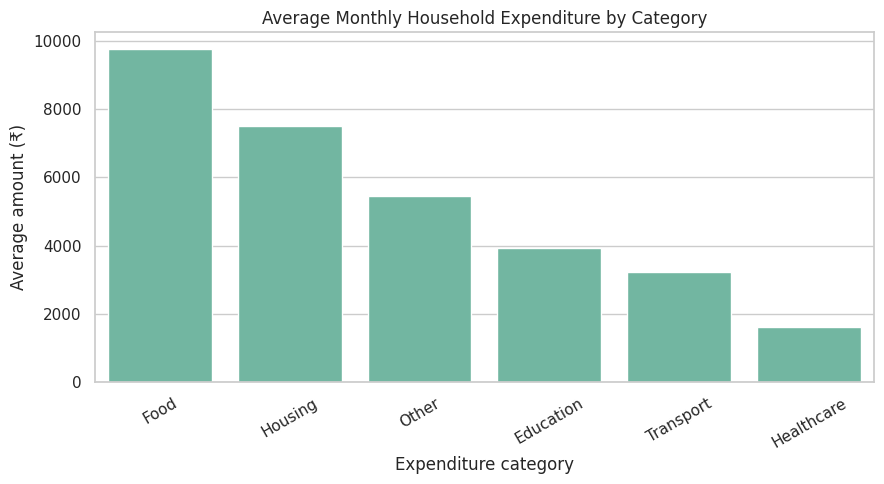

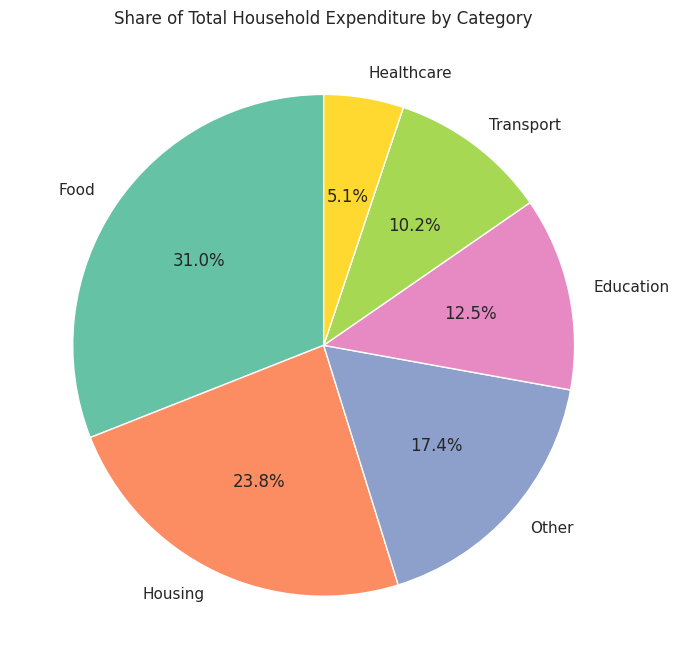

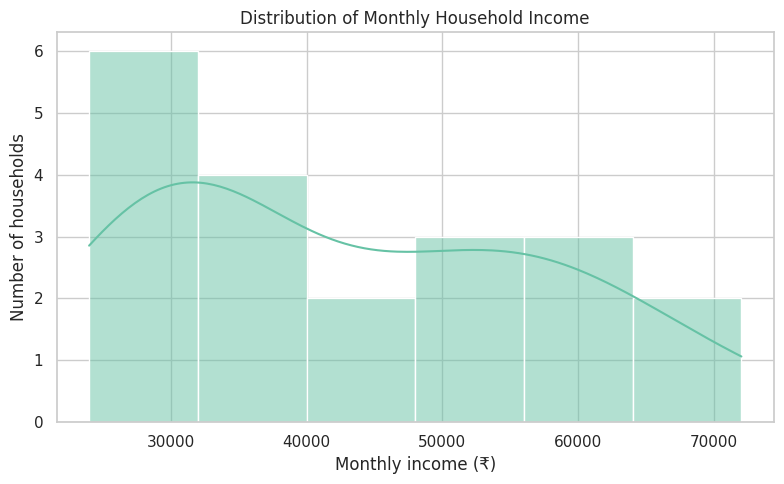

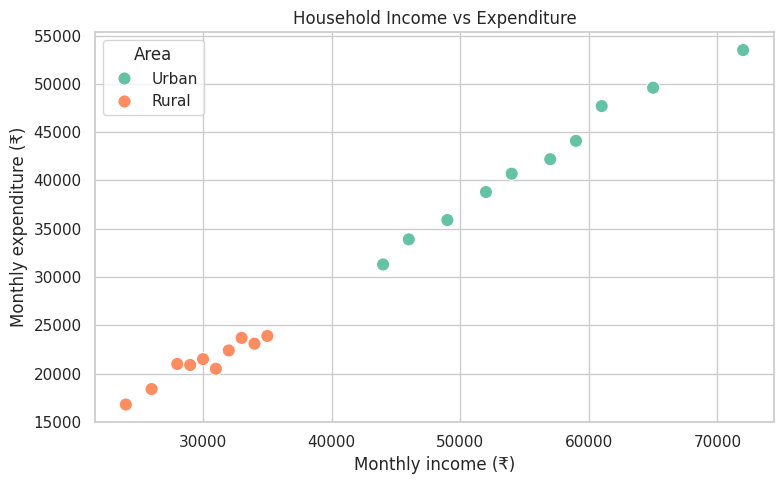

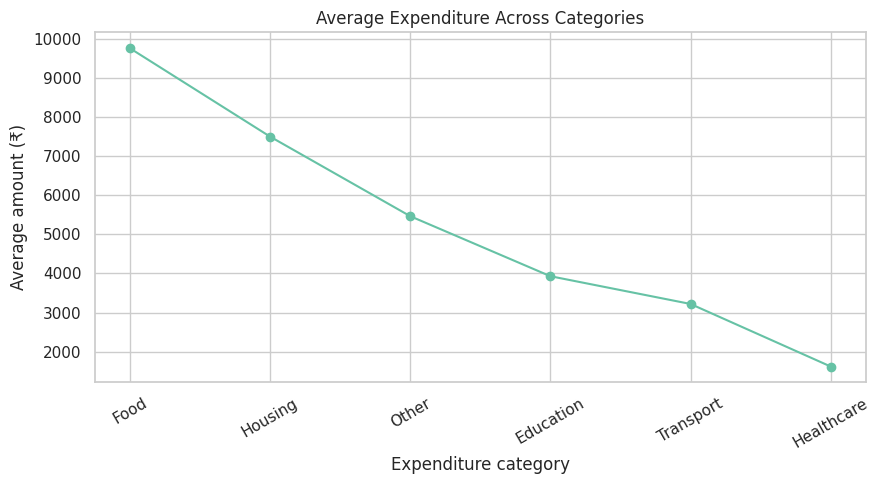

In [ ]:
category_totals = df[expense_columns].sum().sort_values(ascending=False)
category_means = df[expense_columns].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=category_means.index, y=category_means.values)
plt.title("Average Monthly Household Expenditure by Category")
plt.xlabel("Expenditure category")
plt.ylabel("Average amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))
plt.pie(category_totals.values, labels=category_totals.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Total Household Expenditure by Category")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(df["Income"], bins=6, kde=True)
plt.title("Distribution of Monthly Household Income")
plt.xlabel("Monthly income (₹)")
plt.ylabel("Number of households")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Income", y="Expenditure", hue="Area", s=90)
plt.title("Household Income vs Expenditure")
plt.xlabel("Monthly income (₹)")
plt.ylabel("Monthly expenditure (₹)")
plt.legend(title="Area")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(category_means.index, category_means.values, marker="o")
plt.title("Average Expenditure Across Categories")
plt.xlabel("Expenditure category")
plt.ylabel("Average amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 9. Advanced Seaborn visualizations

A box plot shows the spread of values and possible outliers. A violin plot shows the distribution shape. A heatmap displays numeric relationships using colors. A pairplot compares multiple numeric variables.

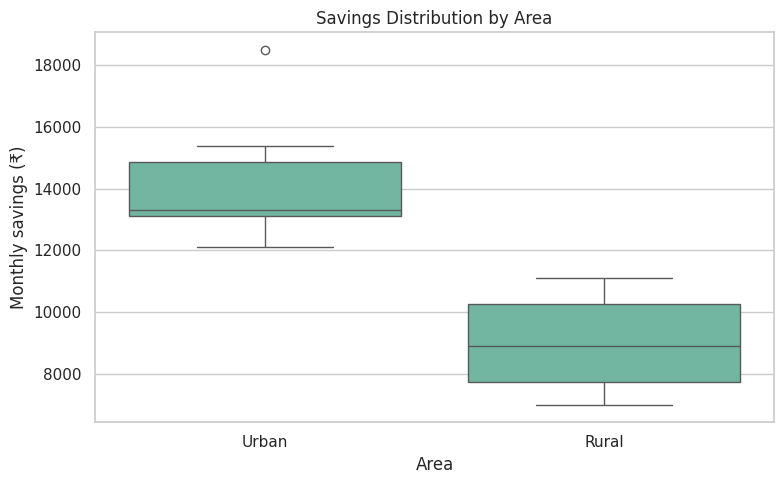

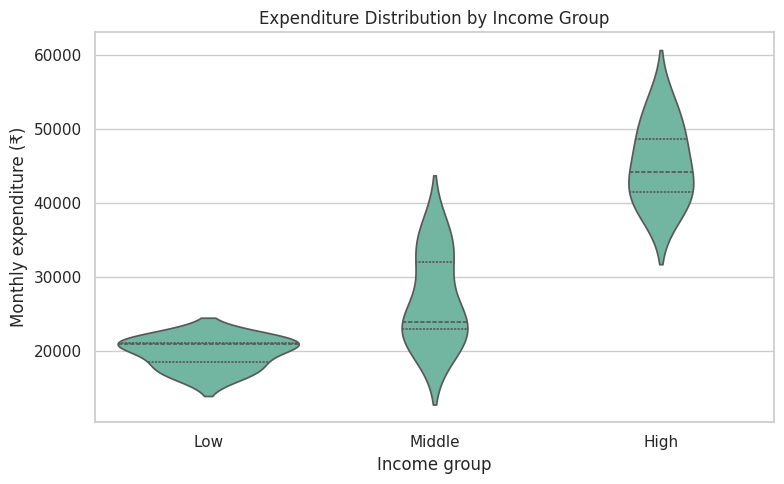

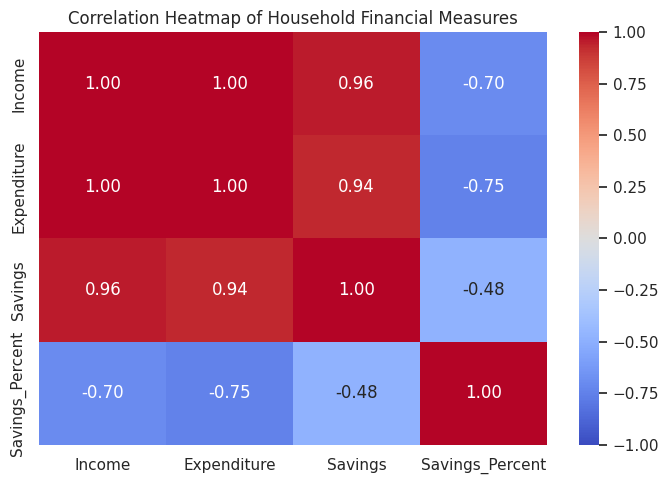

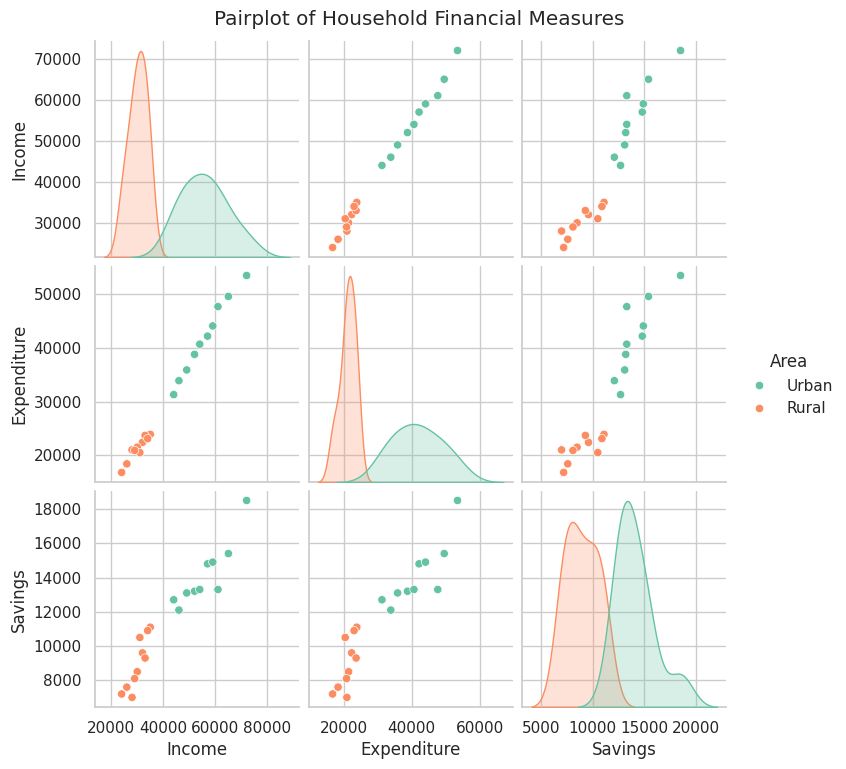

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Area", y="Savings")
plt.title("Savings Distribution by Area")
plt.xlabel("Area")
plt.ylabel("Monthly savings (₹)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Income_Group", y="Expenditure", inner="quartile")
plt.title("Expenditure Distribution by Income Group")
plt.xlabel("Income group")
plt.ylabel("Monthly expenditure (₹)")
plt.tight_layout()
plt.show()

numeric_columns = ["Income", "Expenditure", "Savings", "Savings_Percent"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_columns].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap of Household Financial Measures")
plt.tight_layout()
plt.show()

sns.pairplot(df[["Income", "Expenditure", "Savings", "Area"]], hue="Area")
plt.suptitle("Pairplot of Household Financial Measures", y=1.02)
plt.show()

## 10. Hierarchical indexing, merging and reshaping

These are useful when data comes in multiple tables. Here we create a small second table for practice.

In [ ]:
# Multi-level index (State and Area)
multi_index_df = df.set_index(["State", "Area"]).sort_index()
display(multi_index_df[["Income", "Expenditure"]].head(8))

# Create a small household profile table and merge it with the main data
profile = df[["Household_ID", "State", "Area"]].copy()
profile["Survey_Year"] = 2025

merged_df = pd.merge(df, profile[["Household_ID", "Survey_Year"]], on="Household_ID", how="left")
display(merged_df[["Household_ID", "State", "Survey_Year", "Income", "Expenditure"]].head())

# Concatenation: combine two parts of a table
combined_df = pd.concat([df.head(5), df.tail(5)], ignore_index=True)
print("Rows after concatenating first and last five records:", len(combined_df))

# Pivot: average expenditure by area
pivot_df = df.pivot_table(index="Area", values=expense_columns, aggfunc="mean", observed=False).round(0)
display(pivot_df)

# stack/unstack demonstration using the pivot table
stacked = pivot_df.stack()
print("Stacked view:")
display(stacked.head(10))
print("Unstacked view:")
display(stacked.unstack().head())

Income  Expenditure
State          Area                      
Andhra Pradesh Rural   26000        18400
               Urban   46000        33900
               Urban   44000        31300
Karnataka      Rural   32000        22400
               Rural   29000        20900
               Urban   49000        35900
Kerala         Rural   31000        20500
               Urban   57000        42200

,Household_ID,State,Survey_Year,Income,Expenditure
0,H01,Telangana,2025,52000,38800
1,H02,Telangana,2025,28000,21000
2,H03,Andhra Pradesh,2025,46000,33900
3,H04,Karnataka,2025,32000,22400
4,H05,Maharashtra,2025,61000,47700


Rows after concatenating first and last five records: 10


,Education,Food,Healthcare,Housing,Other,Transport
Area,,,,,,
Rural,2640.0,8150.0,1270.0,3600.0,3730.0,1830.0
Urban,5220.0,11370.0,1970.0,11400.0,7200.0,4610.0


Stacked view:


Area             
Rural  Education      2640.0
       Food           8150.0
       Healthcare     1270.0
       Housing        3600.0
       Other          3730.0
       Transport      1830.0
Urban  Education      5220.0
       Food          11370.0
       Healthcare     1970.0
       Housing       11400.0
dtype: float64

Unstacked view:


,Education,Food,Healthcare,Housing,Other,Transport
Area,,,,,,
Rural,2640.0,8150.0,1270.0,3600.0,3730.0,1830.0
Urban,5220.0,11370.0,1970.0,11400.0,7200.0,4610.0


## 11. Time-series analysis and resampling

The illustrative household table does not contain repeated monthly observations, so it cannot support a genuine trend over time. The next section creates a clearly labelled **practice-only monthly example** to demonstrate date conversion, date indexing, selection and resampling. Do not interpret this as observed survey data.

Select January to June:


,Income,Expenditure,Savings
Date,,,
2025-01-01,42000,30000,12000
2025-02-01,43000,30500,12500
2025-03-01,42000,29800,12200
2025-04-01,44000,31000,13000
2025-05-01,44500,31500,13000
2025-06-01,45000,32000,13000


Quarterly averages using resampling:


,Income,Expenditure,Savings
Date,,,
2025-01-01,42333.0,30100.0,12233.0
2025-04-01,44500.0,31500.0,13000.0
2025-07-01,45500.0,32167.0,13333.0
2025-10-01,48333.0,33500.0,14833.0


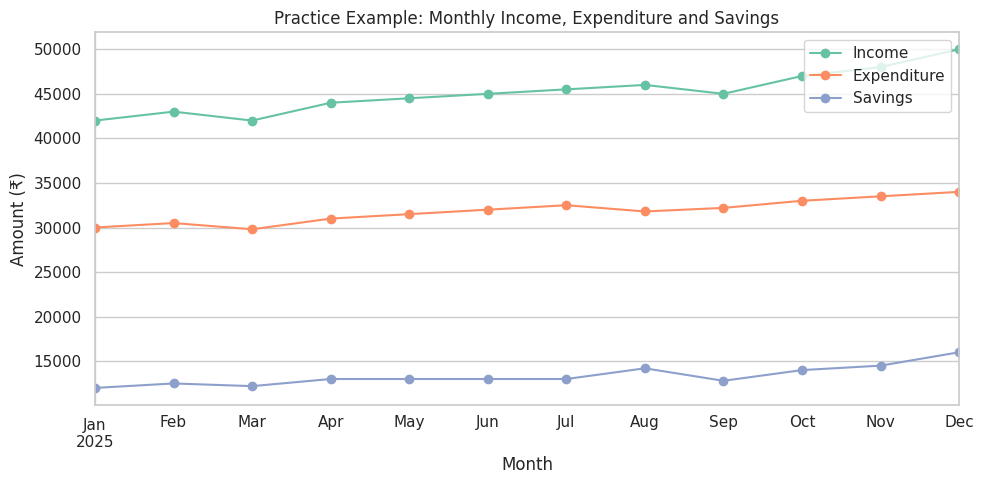

In [ ]:
monthly_demo = pd.DataFrame({
    "Date": pd.date_range("2025-01-01", periods=12, freq="MS"),
    "Income": [42000, 43000, 42000, 44000, 44500, 45000, 45500, 46000, 45000, 47000, 48000, 50000],
    "Expenditure": [30000, 30500, 29800, 31000, 31500, 32000, 32500, 31800, 32200, 33000, 33500, 34000]
})
monthly_demo["Date"] = pd.to_datetime(monthly_demo["Date"])
monthly_demo = monthly_demo.set_index("Date")
monthly_demo["Savings"] = monthly_demo["Income"] - monthly_demo["Expenditure"]

print("Select January to June:")
display(monthly_demo.loc["2025-01":"2025-06"])

print("Quarterly averages using resampling:")
display(monthly_demo.resample("QS").mean().round(0))

monthly_demo[["Income", "Expenditure", "Savings"]].plot(figsize=(10, 5), marker="o")
plt.title("Practice Example: Monthly Income, Expenditure and Savings")
plt.xlabel("Month")
plt.ylabel("Amount (₹)")
plt.tight_layout()
plt.show()

,Survey_Year,Area,MPCE_Rupees
0,2022-23,Rural,3773
1,2022-23,Urban,6459
2,2023-24,Rural,4122
3,2023-24,Urban,6996


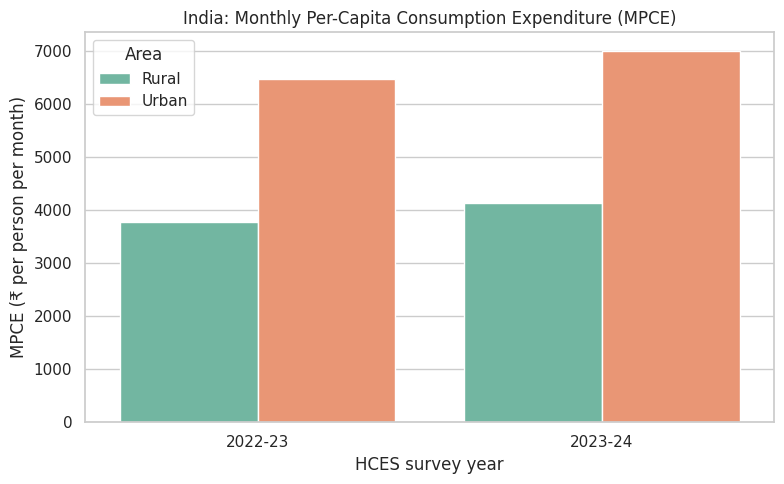

Area,Rural,Urban,Urban_Rural_Difference,Urban_Rural_Ratio
Survey_Year,,,,
2022-23,3773,6459,2686,1.71
2023-24,4122,6996,2874,1.70


In [ ]:
# Rounded official all-India MPCE values (₹ per person per month) from HCES factsheets.
# Verify the exact values and survey year in the official factsheet before final submission.
official_mpce = pd.DataFrame({
    "Survey_Year": ["2022-23", "2022-23", "2023-24", "2023-24"],
    "Area": ["Rural", "Urban", "Rural", "Urban"],
    "MPCE_Rupees": [3773, 6459, 4122, 6996]
})

display(official_mpce)

plt.figure(figsize=(8, 5))
sns.barplot(data=official_mpce, x="Survey_Year", y="MPCE_Rupees", hue="Area")
plt.title("India: Monthly Per-Capita Consumption Expenditure (MPCE)")
plt.xlabel("HCES survey year")
plt.ylabel("MPCE (₹ per person per month)")
plt.legend(title="Area")
plt.tight_layout()
plt.show()

official_pivot = official_mpce.pivot(index="Survey_Year", columns="Area", values="MPCE_Rupees")
official_pivot["Urban_Rural_Difference"] = official_pivot["Urban"] - official_pivot["Rural"]
official_pivot["Urban_Rural_Ratio"] = (official_pivot["Urban"] / official_pivot["Rural"]).round(2)
display(official_pivot)

## 13. Key findings generated from the illustrative household data

The output below is calculated from the 20 practice records. Treat these findings as examples of how to report results, not as facts about all Indian households.

In [ ]:
highest_category = df[expense_columns].sum().idxmax()
lowest_category = df[expense_columns].sum().idxmin()
average_income = df["Income"].mean()
average_expense = df["Expenditure"].mean()
average_savings = df["Savings"].mean()
positive_savings_count = int((df["Savings"] > 0).sum())
income_expense_corr = df["Income"].corr(df["Expenditure"])

print(f"Average monthly income in practice data: ₹{average_income:,.0f}")
print(f"Average monthly expenditure in practice data: ₹{average_expense:,.0f}")
print(f"Average monthly savings in practice data: ₹{average_savings:,.0f}")
print(f"Households with positive savings: {positive_savings_count} out of {len(df)}")
print(f"Largest total spending category in practice data: {highest_category}")
print(f"Smallest total spending category in practice data: {lowest_category}")
print(f"Correlation between income and expenditure in practice data: {income_expense_corr:.2f}")

Average monthly income in practice data: ₹43,050
Average monthly expenditure in practice data: ₹31,495
Average monthly savings in practice data: ₹11,555
Households with positive savings: 20 out of 20
Largest total spending category in practice data: Food
Smallest total spending category in practice data: Healthcare
Correlation between income and expenditure in practice data: 1.00
